# Predicting Online Purchases — PRD 3.0
### DSA211 · Prediction-only · four sequential classification pathways

**Research question.** How accurately can browsing-session characteristics distinguish sessions ending in a purchase (Revenue=1), and which defensible taught-classifier specification gives the best **mean five-fold training ROC-AUC**?

**Design.** Start with four all-17 feature-timing diagnostics, establish four 16-source operational baselines, then evaluate an EDA-motivated 3–5 step sequence independently for Logit, LDA, Gaussian NB and Bernoulli NB. Use a local **one-standard-error** criterion to retain/reject each modification. Select one finalist per pathway, then a winner by mean CV AUC.

**Secondary illustration.** A hypothetical sales-agent upsell uses **S$3** assistance cost, **30%** conditional upsell success and **S$50** gross margin. The resulting **0.20** cost cutoff is an *assumption-based decision threshold*, not empirical evidence of upsell uplift. Source: [approved PRD v3.0](docs/PRD_v3.md).

## 0. Fixed analysis protocol
**Purpose.** Make development comparisons reproducible and preserve the reserved set for one frozen v3 check.

**Method.** Use the v2 stratified 80/20 partition (seed 42) and the same five shuffled stratified training folds (seed 42) for every specification. Any median, category pooling, encoding, scaling or penalty parameter is fitted **inside the applicable fold**; L4/D4 tune on three *inner* training folds. The project already exposed the reserved set in historical versions, so v3's check is **not pristine across the entire development history**.

**Interpretation.** ROC-AUC measures discrimination, AP contextualises minority-class ranking and does not establish probability calibration or treatment effects. The selected model cannot be revised after checking v3's reserved-set result.

In [1]:
from pathlib import Path
import hashlib, json, warnings, platform, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt, scipy, sklearn
from scipy import stats
from scipy.special import logsumexp
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.exceptions import ConvergenceWarning
import statsmodels.api as sm
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, log_loss, roc_curve, confusion_matrix

RUN_START=time.perf_counter()
SEED=42; TEST_FRAC=.20; K=5
TARGET='Revenue'
NUMERIC_ALL=['Administrative','Administrative_Duration','Informational','Informational_Duration',
 'ProductRelated','ProductRelated_Duration','BounceRates','ExitRates','PageValues','SpecialDay']
CAT=['Month','OperatingSystems','Browser','Region','TrafficType','VisitorType']
ACTIVITY=['Administrative','Administrative_Duration','Informational','Informational_Duration','ProductRelated','ProductRelated_Duration']
NUMERIC_SAFE=[x for x in NUMERIC_ALL if x!='PageValues']
ALL=NUMERIC_ALL+CAT+['Weekend']; SAFE=NUMERIC_SAFE+CAT+['Weekend']
EXPECTED=set(ALL+[TARGET])
root_candidates=[Path('data/uci_468.csv'),Path('../data/uci_468.csv')]
data_path=next((p for p in root_candidates if p.is_file()),None)
if data_path is None: raise FileNotFoundError('Run from repository root or a direct child directory; expected data/uci_468.csv')
ROOT=data_path.parent.parent if data_path.parent.name=='data' else data_path.parent.parent
ARTIFACTS=ROOT/'artifacts'; ARTIFACTS.mkdir(exist_ok=True)
WORK=ROOT/'work'; WORK.mkdir(exist_ok=True)
PROGRESS_LOG=WORK/'baseline_progress.jsonl'; PROGRESS_LOG.write_text('')
def mark_progress(candidate,fold,event,**details):
    record={'candidate':candidate,'fold':fold,'event':event,'elapsed_seconds':round(time.perf_counter()-RUN_START,3),**details}
    with PROGRESS_LOG.open('a') as f: f.write(json.dumps(record,default=str)+'\n')
print(f'Python {platform.python_version()} | pandas {pd.__version__} | NumPy {np.__version__} | SciPy {scipy.__version__} | scikit-learn {sklearn.__version__}')
print('Operational selection uses mean five-fold training ROC-AUC; AP and fold variation are supporting evidence. Threshold diagnostics use only winner training OOF predictions.')


Python 3.12.15 | pandas 3.0.6 | NumPy 2.5.4 | SciPy 1.18.1 | scikit-learn 1.9.1
Operational selection uses mean five-fold training ROC-AUC; AP and fold variation are supporting evidence. Threshold diagnostics use only winner training OOF predictions.


## 1. Data quality and split

**Purpose.** Verify source completeness and establish training/holdout membership.

**Method.** Check missingness, outcome balance and duplicates; preserve all 12,330 sessions. Use training rows only for EDA, candidate selection and threshold comparisons.


In [2]:
raw=pd.read_csv(data_path); raw.insert(0,'_row_id',np.arange(len(raw),dtype=int))
source_hash=hashlib.sha256(data_path.read_bytes()).hexdigest()
if raw.shape!=(12330,19): raise ValueError(f'Expected 12,330 rows and 18 source columns, found {raw.shape}')
if set(raw.columns)-{'_row_id'} != EXPECTED: raise ValueError(f'Unexpected source columns: {sorted((set(raw.columns)-{"_row_id"}) ^ EXPECTED)}')
if raw[TARGET].isna().any() or not set(raw[TARGET].unique()).issubset({0,1,False,True}): raise ValueError('Revenue must be complete binary 0/1')
raw[TARGET]=raw[TARGET].astype(int)
if raw[NUMERIC_ALL].isna().any().any() or not np.isfinite(raw[NUMERIC_ALL].to_numpy(float)).all(): raise ValueError('Numeric source predictors must be complete and finite')
blank=raw[CAT].astype('string').apply(lambda s:s.str.strip().eq('').sum())
missing=raw.drop(columns='_row_id').isna().sum()
if missing.any() or blank.any(): raise ValueError('Unexpected missing values or blank nominal markers; inspect source before modelling')
if raw['Weekend'].isna().any() or not set(raw['Weekend'].unique()).issubset({0,1,False,True}): raise ValueError('Weekend must be complete binary 0/1')
quality=pd.DataFrame({'dtype':raw.drop(columns='_row_id').dtypes.astype(str),'missing':missing,
                      'blank nominal':blank.reindex(missing.index,fill_value=0),'unique':raw.drop(columns='_row_id').nunique()})
print('Source shape (rows, columns):',(len(raw),len(raw.columns)-1),'SHA-256:',source_hash)
print('Duplicate excess / unique full rows:',int(raw.duplicated(subset=raw.columns.drop('_row_id')).sum()),'/',raw.drop(columns='_row_id').drop_duplicates().shape[0])
print(f'Missing: {int(missing.sum())}; blank nominal: {int(blank.sum())}')
display(raw[TARGET].value_counts().sort_index().rename_axis(TARGET).to_frame('sessions').assign(share=lambda d:d.sessions/len(raw)))
dup=raw.loc[raw.duplicated(subset=raw.columns.drop('_row_id'),keep='first')]
print(f'Excess duplicates: {len(dup)}; duplicate outcomes:',dup[TARGET].value_counts().sort_index().to_dict())

train_ids,test_ids=train_test_split(raw['_row_id'].to_numpy(),test_size=TEST_FRAC,
    stratify=raw[TARGET].to_numpy(),random_state=SEED)
train_ids=np.sort(train_ids); test_ids=np.sort(test_ids)
pd.DataFrame({'row_id':train_ids,'partition':'train'}).to_csv(ARTIFACTS/'train_row_ids.csv',index=False)
pd.DataFrame({'row_id':test_ids,'partition':'test'}).to_csv(ARTIFACTS/'test_row_ids.csv',index=False)
train=raw.set_index('_row_id').loc[train_ids].copy()
y_train=train.pop(TARGET).astype(int)
X_train=train[ALL].copy()
X_train[CAT]=X_train[CAT].astype('string')
X_train['Weekend']=X_train['Weekend'].astype(int)
del raw,dup
cv=StratifiedKFold(n_splits=K,shuffle=True,random_state=SEED)
FOLD_INDICES=list(cv.split(np.zeros(len(y_train)),y_train))
fold_map=[]
for fold,(fit_idx,val_idx) in enumerate(FOLD_INDICES,1):
    fold_map += [{'row_id':int(X_train.index[i]),'fold':fold,'role':'fit'} for i in fit_idx]
    fold_map += [{'row_id':int(X_train.index[i]),'fold':fold,'role':'validation'} for i in val_idx]
pd.DataFrame(fold_map).to_csv(ARTIFACTS/'cv_fold_row_ids.csv',index=False)
print(f'Training={len(X_train):,}; holdout IDs recorded={len(test_ids):,}; purchases={y_train.sum():,} ({y_train.mean():.2%}).')


Source shape (rows, columns): (12330, 18) SHA-256: b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9
Duplicate excess / unique full rows: 125 / 12205
Missing: 0; blank nominal: 0


,sessions,share
Revenue,,
0,10422,0.845255
1,1908,0.154745


Excess duplicates: 125; duplicate outcomes: {0: 125}


Training=9,864; holdout IDs recorded=2,466; purchases=1,526 (15.47%).


## 2. Numerical EDA

**Purpose.** Identify skew and excess zeros.

**Method.** Display median, zero share and skewness, with representative histograms.

**Implication.** Test log1p for long tails and fold-fitted presence indicators for zero-heavy activity.


,median,zero share,skew
Administrative,1.000,0.467,1.967
Administrative_Duration,8.000,0.477,5.679
Informational,0.000,0.785,4.142
Informational_Duration,0.000,0.805,7.702
ProductRelated,18.000,0.003,4.372
ProductRelated_Duration,600.537,0.062,8.009
BounceRates,0.003,0.448,2.924
ExitRates,0.025,0.006,2.130
PageValues,0.000,0.778,6.187
SpecialDay,0.000,0.897,3.261


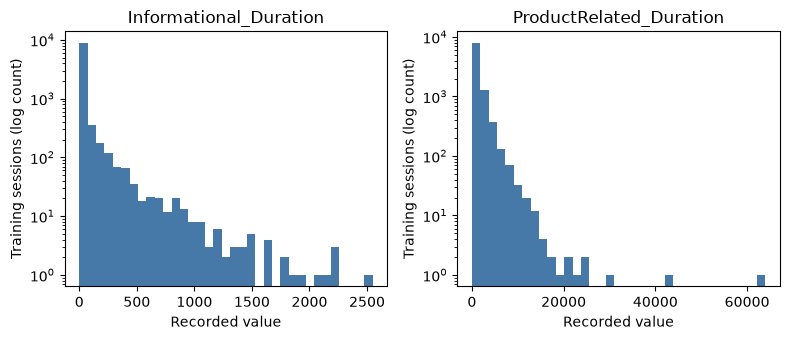

In [3]:
Xtr=X_train; ytr=y_train
num_summary=pd.DataFrame({'median':Xtr[NUMERIC_ALL].median(),'zero share':Xtr[NUMERIC_ALL].eq(0).mean(),
                          'skew':Xtr[NUMERIC_ALL].skew(),'buyer median':Xtr.loc[ytr.eq(1),NUMERIC_ALL].median(),
                          'nonbuyer median':Xtr.loc[ytr.eq(0),NUMERIC_ALL].median()})
display(num_summary[['median','zero share','skew']].round(3))
fig,axes=plt.subplots(1,2,figsize=(8,3.5))
for ax,col in zip(axes.flat,['Informational_Duration','ProductRelated_Duration']):
    ax.hist(Xtr[col],bins=35,log=True,color='#4779a8'); ax.set(title=col,xlabel='Recorded value',ylabel='Training sessions (log count)')
plt.tight_layout(); plt.show()
long_tail=num_summary.loc[ACTIVITY,'skew']


## 3. Categorical EDA

**Purpose.** Compare observed buying rates across nominal levels.

**Method.** Summarise sparsity and show Month/VisitorType rates on training rows.

**Implication.** Encode nominal levels in each CV fit; avoid over-interpreting small groups.


In [4]:
cat_summary=[]
for col in CAT:
    tab=Xtr.assign(Revenue=ytr).groupby(col,observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),buyer_rate=('Revenue','mean'))
    cat_summary.append({'feature':col,'levels':len(tab),'small levels <50':int((tab.sessions<50).sum()),
      'small-level sessions':int(tab.loc[tab.sessions<50,'sessions'].sum()),
      'buyer-rate range':f"{tab.buyer_rate.min():.1%}–{tab.buyer_rate.max():.1%}"})
display(pd.DataFrame(cat_summary).set_index('feature')[['levels','small levels <50','buyer-rate range']])
for col in ['Month','VisitorType']:
    tab=Xtr.assign(Revenue=ytr).groupby(col,observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),buyer_rate=('Revenue','mean')).sort_values('sessions',ascending=False)
    print(f'Training group counts and observed buyer rates: {col}')
    display(tab[['sessions','buyer_rate']].round(3))
rare=[]
for col in ['TrafficType','Browser','Region']:
    tab=Xtr.assign(Revenue=ytr).groupby(col,observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),buyer_rate=('Revenue','mean'))
    small=tab[tab.sessions<50]
    rare.append({'feature':col,'levels below n=50':len(small),'total levels':len(tab),
                 'rare-cell rate range':f"{small.buyer_rate.min():.1%}–{small.buyer_rate.max():.1%}" if len(small) else 'none'})
vtm=Xtr.assign(Revenue=ytr).groupby(['VisitorType','Month'],observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),buyer_rate=('Revenue','mean')).reset_index()
special=Xtr.assign(Revenue=ytr).groupby('SpecialDay',observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),buyer_rate=('Revenue','mean'))


,levels,small levels <50,buyer-rate range
feature,,,
Month,10,0,1.4%–24.8%
OperatingSystems,8,3,10.6%–25.0%
Browser,13,4,0.0%–42.9%
Region,9,0,14.2%–17.0%
TrafficType,20,9,0.0%–33.3%
VisitorType,3,0,14.0%–24.7%


Training group counts and observed buyer rates: Month


,sessions,buyer_rate
Month,,
May,2703,0.108
Nov,2360,0.248
Mar,1538,0.103
Dec,1391,0.132
Oct,444,0.221
Sep,368,0.204
Jul,344,0.134
Aug,342,0.178
June,228,0.101


Training group counts and observed buyer rates: VisitorType


,sessions,buyer_rate
VisitorType,,
Returning_Visitor,8443,0.140
New_Visitor,1347,0.247
Other,74,0.176


## 4. Predictor relationships and assumptions

**Purpose.** Assess dependence and departure from Gaussian shapes.

**Method.** Check selected within-class correlations and Q–Q plots.

**Implication.** Diagnostics motivate candidates; CV, not visual assumptions alone, evaluates performance.


BounceRates/ExitRates correlations are 0.915 for nonbuyers and 0.723 for buyers; ProductRelated/ProductRelated_Duration are 0.839 and 0.896. These selected differences do not establish unequal full covariance matrices.


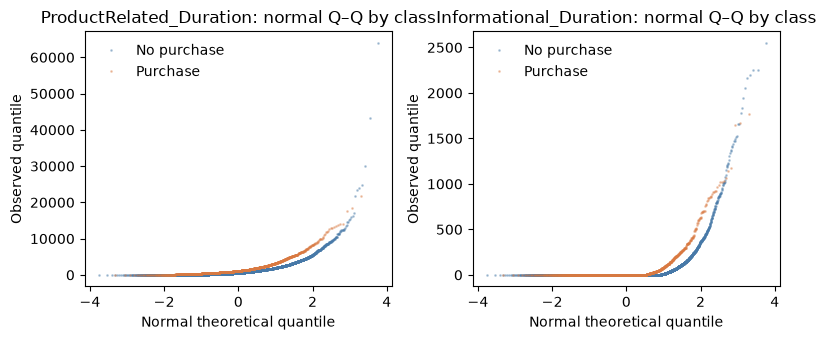

In [5]:
NUM_SAFE=[c for c in NUMERIC_ALL if c!='PageValues']+['Weekend']
for cls in [0,1]:
    corr=Xtr.loc[ytr.eq(cls),NUM_SAFE].corr().abs()
    pairs=corr.where(np.triu(np.ones(corr.shape),k=1).astype(bool)).stack().sort_values(ascending=False).head(5)
print('BounceRates/ExitRates correlations are {:.3f} for nonbuyers and {:.3f} for buyers; ProductRelated/ProductRelated_Duration are {:.3f} and {:.3f}. These selected differences do not establish unequal full covariance matrices.'.format(
 Xtr.loc[ytr.eq(0),['BounceRates','ExitRates']].corr().iloc[0,1],Xtr.loc[ytr.eq(1),['BounceRates','ExitRates']].corr().iloc[0,1],
 Xtr.loc[ytr.eq(0),['ProductRelated','ProductRelated_Duration']].corr().iloc[0,1],Xtr.loc[ytr.eq(1),['ProductRelated','ProductRelated_Duration']].corr().iloc[0,1]))
fig,axes=plt.subplots(1,2,figsize=(8,3.5))
for ax,col in zip(axes,['ProductRelated_Duration','Informational_Duration']):
    for cls,label,color in [(0,'No purchase','#4779a8'),(1,'Purchase','#d97941')]:
        vals=Xtr.loc[ytr.eq(cls),col].to_numpy()
        (osm,osr),_=stats.probplot(vals,dist='norm',fit=True)
        ax.plot(osm,osr,'.',ms=2,alpha=.35,label=label,color=color)
    ax.set(title=f'{col}: normal Q–Q by class',xlabel='Normal theoretical quantile',ylabel='Observed quantile'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

def marginal_elogit(col, bins=8):
    z=pd.DataFrame({'x':Xtr[col],'buyer':ytr}); z['bin']='zero'; positive=z.x.gt(0)
    if positive.any(): z.loc[positive,'bin']=pd.qcut(z.loc[positive,'x'],bins,duplicates='drop').astype(str)
    out=z.groupby('bin',observed=True).agg(n=('buyer','size'),mean_x=('x','mean'),buyers=('buyer','sum'),rate=('buyer','mean')).reset_index()
    out['empirical_logit']=np.log((out.buyers+.5)/(out.n-out.buyers+.5))
    return out.sort_values('mean_x')


In [6]:
# Reuse v2's source variables, data split, folds and basic model-evaluation contract.
# New v3 changes are deliberately isolated in this fold-fitted representation and evaluator.
from sklearn.model_selection import GridSearchCV
from sklearn.calibration import calibration_curve

V3_ART=ARTIFACTS/'prd_v3'
V3_ART.mkdir(parents=True,exist_ok=True)
C_GRID=[0.05,0.2,1.0,5.0,20.0]
SHRINKAGE_GRID=[0.0,0.1,0.3,0.6,0.9]
RARE_MIN_COUNT=50
INNER_FOLDS=3
FAMILY_ORDER=['Logit','LDA','GaussianNB','BernoulliNB']

class FoldSafeFeatures(BaseEstimator, TransformerMixin):
    """Train-fold-only feature engineering. Categorical levels are never treated as ordinal."""
    def __init__(self, family='Logit', columns=(), log_activity=False,
                 presence=False, rare_pool=False, special_binary=False,
                 drop_features=(), median_cols=(), scale=False):
        self.family=family
        self.columns=columns
        self.log_activity=log_activity
        self.presence=presence
        self.rare_pool=rare_pool
        self.special_binary=special_binary
        self.drop_features=drop_features
        self.median_cols=median_cols
        self.scale=scale

    def _blocks(self,X):
        active=[c for c in self.columns if c not in self.drop_features]
        cats=[c for c in CAT if c in active]
        nums=[c for c in active if c not in cats]
        z=pd.DataFrame(index=X.index)
        for c in nums:
            value=X[c].astype(float)
            if self.family=='BernoulliNB':
                if c in self.median_cols:
                    z[c]=(value>self.medians_[c]).astype(float)
                elif c=='Weekend':
                    z[c]=value
                else:
                    z[c]=(value>0).astype(float)
            elif self.special_binary and c=='SpecialDay':
                z[c]=(value>0).astype(float)
            elif self.log_activity and c in ACTIVITY:
                z[c]=np.log1p(value)
            else:
                z[c]=value
        if self.presence:
            for c in ('Informational','Informational_Duration'):
                if c in active:
                    z[c+'__positive']=(X[c].astype(float)>0).astype(float)
        cat=pd.DataFrame(index=X.index)
        for c in cats:
            values=X[c].astype(str)
            if self.rare_pool and c in ('Browser','TrafficType'):
                values=values.where(values.isin(self.major_levels_[c]),'__OTHER__')
            cat[c]=values
        return z,cat

    def fit(self,X,y=None):
        self.n_features_in_=X.shape[1]
        self.feature_names_in_=np.asarray(X.columns,dtype=object)
        self.major_levels_={}
        for c in ('Browser','TrafficType'):
            if c in X and self.rare_pool:
                counts=X[c].astype(str).value_counts()
                self.major_levels_[c]=set(counts.index[counts>=RARE_MIN_COUNT])
        self.medians_={c:float(X[c].median()) for c in self.median_cols}
        num,cat=self._blocks(X)
        self.numeric_names_=list(num.columns)
        self.categorical_names_=list(cat.columns)
        self.encoder_=OneHotEncoder(
            drop='first' if self.family in ('Logit','LDA') else None,
            handle_unknown='ignore',sparse_output=False
        )
        if self.categorical_names_:
            self.encoder_.fit(cat)
        transformed=self._encode(num,cat)
        if self.scale:
            self.scaler_=StandardScaler().fit(transformed)
        return self

    def _encode(self,num,cat):
        blocks=[num.to_numpy(dtype=float)]
        if self.categorical_names_:
            blocks.append(self.encoder_.transform(cat))
        Z=np.column_stack(blocks)
        if not np.isfinite(Z).all():
            raise ValueError('Non-finite preprocessing output')
        return Z

    def transform(self,X):
        num,cat=self._blocks(X)
        Z=self._encode(num,cat)
        return self.scaler_.transform(Z) if self.scale else Z

    def get_feature_names_out(self,input_features=None):
        names=list(self.numeric_names_)
        if self.categorical_names_:
            names+=list(self.encoder_.get_feature_names_out(self.categorical_names_))
        return np.asarray(names,dtype=object)

def build_model(family,config=None,columns=SAFE):
    cfg=dict(config or {})
    tune=cfg.pop('tune',None)
    pre=FoldSafeFeatures(family=family,columns=tuple(columns),**cfg)
    if family=='Logit':
        if tune=='logit':
            clf=LogisticRegression(solver='lbfgs',max_iter=1600,tol=1e-6)
        else:
            clf=LogisticRegression(C=np.inf,solver='newton-cg',tol=1e-8,max_iter=2000)
    elif family=='LDA':
        clf=LinearDiscriminantAnalysis(solver='lsqr' if tune=='lda' else 'svd')
    elif family=='GaussianNB':
        clf=GaussianNB()
    elif family=='BernoulliNB':
        clf=BernoulliNB(binarize=None)
    else:
        raise ValueError(family)
    pipe=Pipeline([('pre',pre),('clf',clf)])
    if tune:
        params={'clf__C':C_GRID} if tune=='logit' else {'clf__shrinkage':SHRINKAGE_GRID}
        inner=StratifiedKFold(n_splits=INNER_FOLDS,shuffle=True,random_state=SEED)
        return GridSearchCV(pipe,params,cv=inner,scoring='roc_auc',n_jobs=1,refit=True,error_score='raise')
    return pipe

def make_pipeline(columns,family,estimator=None):
    if estimator is not None:
        raise ValueError('v3 uses explicit configurations, not replacement estimators')
    return build_model(family,{},columns)

def compact_numerical_label(result):
    return result.get('numerical_status','UNKNOWN')

def run_spec(label,family,columns,pipeline_factory=None):
    oof=np.full(len(ytr),np.nan)
    folds=[]; warning_rows=[]
    for fold,(fit_idx,val_idx) in enumerate(FOLD_INDICES,1):
        fit_x=Xtr.iloc[fit_idx][columns]
        val_x=Xtr.iloc[val_idx][columns]
        fit_y=ytr.iloc[fit_idx]
        val_y=ytr.iloc[val_idx]
        fitted=pipeline_factory() if pipeline_factory is not None else make_pipeline(columns,family)
        mark_progress(label,fold,'start',n_fit=len(fit_idx),n_validation=len(val_idx))
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            fitted.fit(fit_x,fit_y)
            prob=np.asarray(fitted.predict_proba(val_x)[:,1],dtype=float)
        actual=fitted.best_estimator_ if isinstance(fitted,GridSearchCV) else fitted
        clf=actual.named_steps['clf']
        params=['coef_','intercept_','theta_','var_','class_prior_','feature_log_prob_',
                'means_','priors_','scalings_','class_log_prior_']
        finite=all(np.isfinite(np.asarray(getattr(clf,k),dtype=float)).all()
                   for k in params if hasattr(clf,k))
        if not finite or not np.isfinite(prob).all() or np.any((prob<0)|(prob>1)):
            raise RuntimeError(f'{label} fold {fold}: invalid model parameters/probabilities')
        oof[val_idx]=prob
        for w in caught:
            warning_rows.append({'candidate':label,'fold':fold,
                                 'warning_type':w.category.__name__,
                                 'message':str(w.message)[:350]})
        best=fitted.best_params_ if isinstance(fitted,GridSearchCV) else {}
        row={'candidate':label,'family':family,'fold':fold,'fit_status':'OK',
             'n_fit':len(fit_idx),'n_validation':len(val_idx),
             'roc_auc':float(roc_auc_score(val_y,prob)),
             'average_precision':float(average_precision_score(val_y,prob)),
             'design_rank':np.nan,'design_columns':actual.named_steps['pre'].transform(fit_x.iloc[:1]).shape[1],
             'finite_model_parameters':bool(finite),'finite_probabilities':True,
             'probabilities_in_0_1':True,'inner_cv_best_params':json.dumps(best),
             'numerical_status':'FINITE_WITH_WARNINGS_REVIEW_REQUIRED' if caught else 'FINITE_FIT'}
        folds.append(row)
        mark_progress(label,fold,'complete',roc_auc=row['roc_auc'])
    if np.isnan(oof).any():
        raise RuntimeError(f'{label}: incomplete OOF coverage')
    auc=np.array([x['roc_auc'] for x in folds],dtype=float)
    ap=np.array([x['average_precision'] for x in folds],dtype=float)
    return {'candidate':label,'family':family,'stage':'all17' if len(columns)==len(ALL) else 'operational16',
            'status':'SCORED','numerical_status':'FINITE_WITH_WARNINGS_REVIEW_REQUIRED' if warning_rows else 'FINITE_FIT',
            'folds':folds,'oof':oof,'warnings':warning_rows,'failure':'',
            'mean_fold_auc':float(auc.mean()),
            'fold_auc_sd':float(auc.std(ddof=1)),
            'fold_auc_se':float(auc.std(ddof=1)/np.sqrt(K)),
            'mean_fold_ap':float(ap.mean()),
            'fold_ap_sd':float(ap.std(ddof=1)),
            'fold_ap_se':float(ap.std(ddof=1)/np.sqrt(K)),
            'pooled_oof_auc':float(roc_auc_score(ytr,oof)),
            'pooled_oof_ap':float(average_precision_score(ytr,oof))}

RESULTS={}; FOLD_ROWS=[]; WARNING_ROWS=[]

## 5. Four all-17 first-pass models

**Purpose.** Start with every source predictor.

**Method.** Compare Logit, GaussianNB, BernoulliNB and LDA using common training folds.

**Implication.** This is a diagnostic pass, not the operational model selection.


In [7]:
# A5 — diagnostic first pass, all 17 predictors
for family in ['Logit','GaussianNB','BernoulliNB','LDA']:
    label=f'All17 | {family}'
    print('Fitting',label,flush=True)
    RESULTS[label]=run_spec(label,family,ALL)
    FOLD_ROWS.extend(RESULTS[label]['folds']); WARNING_ROWS.extend(RESULTS[label]['warnings'])
ALL17=pd.DataFrame([{'candidate':r['candidate'],'scoring status':r['status'],'numerical status':compact_numerical_label(r),'mean ROC-AUC':r.get('mean_fold_auc',np.nan),
 'AUC SD':r.get('fold_auc_sd',np.nan),'AUC SE':r.get('fold_auc_se',np.nan),'mean AP':r.get('mean_fold_ap',np.nan),
 'pooled OOF AUC':r.get('pooled_oof_auc',np.nan),'warnings':len(r['warnings']),'failure':r['failure']} for r in RESULTS.values() if r['stage']=='all17']).set_index('candidate')
display(ALL17[['mean ROC-AUC','AUC SD','mean AP']].round(4))
fold_diag=pd.DataFrame([x for r in RESULTS.values() if r['stage']=='all17' for x in r['folds']])
all17_audit=fold_diag.groupby('candidate').agg(rank_min=('design_rank','min'),rank_max=('design_rank','max'),
    encoded_columns_min=('design_columns','min'),encoded_columns_max=('design_columns','max'),
    all_parameters_finite=('finite_model_parameters','all'),all_probabilities_in_range=('probabilities_in_0_1','all'))
logit_diag=fold_diag[fold_diag.family.eq('Logit')].copy()


Fitting All17 | Logit


Fitting All17 | GaussianNB


Fitting All17 | BernoulliNB


Fitting All17 | LDA


,mean ROC-AUC,AUC SD,mean AP
candidate,,,
All17 | Logit,0.8897,0.0063,0.6443
All17 | GaussianNB,0.7879,0.0145,0.4334
All17 | BernoulliNB,0.8766,0.0105,0.5345
All17 | LDA,0.8997,0.0033,0.6469


**Interpretation.** `PageValues` may be unavailable when prediction would be required. Exclude it from operational models as a precaution; a strong association alone does not establish leakage.


In [8]:
# PageValues descriptive association on training rows only
pv=Xtr.assign(Revenue=ytr).groupby(Xtr.PageValues.gt(0).map({False:'PageValues = 0',True:'PageValues > 0'})).Revenue.agg(sessions='size',buyers='sum',buyer_rate='mean')
display(pv)
print('The above difference is descriptive. PageValues is excluded from operational predictors because its availability at the intended prediction time is uncertain, not because association proves leakage.')


,sessions,buyers,buyer_rate
PageValues,,,
PageValues = 0,7671,286,0.037283
PageValues > 0,2193,1240,0.565435


The above difference is descriptive. PageValues is excluded from operational predictors because its availability at the intended prediction time is uncertain, not because association proves leakage.


## 6. Four operational baselines

**Purpose.** Evaluate the taught families using the 16 decision-time candidates.

**Method.** Compare baseline ROC-AUC/AP on identical folds; quantify the AUC change from excluding `PageValues`.

**Implication.** Baselines provide the reference for targeted modifications.


In [9]:
# A6 — four operational 16-source-predictor baselines
for family in ['Logit','GaussianNB','BernoulliNB','LDA']:
    label=f'Operational16 | {family}'
    print('Fitting',label,flush=True)
    RESULTS[label]=run_spec(label,family,SAFE)
    FOLD_ROWS.extend(RESULTS[label]['folds']); WARNING_ROWS.extend(RESULTS[label]['warnings'])
OP16=pd.DataFrame([{'candidate':r['candidate'],'scoring status':r['status'],'numerical status':compact_numerical_label(r),'mean ROC-AUC':r.get('mean_fold_auc',np.nan),
 'AUC SD':r.get('fold_auc_sd',np.nan),'AUC SE':r.get('fold_auc_se',np.nan),'mean AP':r.get('mean_fold_ap',np.nan),
 'pooled OOF AUC':r.get('pooled_oof_auc',np.nan),'warnings':len(r['warnings']),'failure':r['failure']} for r in RESULTS.values() if r['stage']=='operational16']).set_index('candidate')
display(OP16[['mean ROC-AUC','AUC SD','mean AP']].round(4))
op16_fold_diag=pd.DataFrame([x for r in RESULTS.values() if r['stage']=='operational16' for x in r['folds']])
op16_audit=op16_fold_diag.groupby('candidate').agg(rank_min=('design_rank','min'),rank_max=('design_rank','max'),
    encoded_columns_min=('design_columns','min'),encoded_columns_max=('design_columns','max'),
    all_parameters_finite=('finite_model_parameters','all'),all_probabilities_in_range=('probabilities_in_0_1','all'))
# Direct same-fold AUC changes quantify the effect of omitting PageValues in each family.
comparison=[]
for family in ['Logit','GaussianNB','BernoulliNB','LDA']:
    a=RESULTS[f'All17 | {family}']; b=RESULTS[f'Operational16 | {family}']
    if a['status']=='SCORED' and b['status']=='SCORED':
        for x,y in zip(a['folds'],b['folds']): comparison.append({'family':family,'fold':x['fold'],'AUC all17':x['roc_auc'],'AUC op16':y['roc_auc'],'op16 minus all17':y['roc_auc']-x['roc_auc']})
PAGE_COMPARE=pd.DataFrame(comparison)
PAGE_SUMMARY=PAGE_COMPARE.groupby('family')['op16 minus all17'].agg(['mean','std']).rename(columns={'mean':'mean AUC delta','std':'fold SD'}).round(4)
display(PAGE_SUMMARY[['mean AUC delta']])


Fitting Operational16 | Logit


Fitting Operational16 | GaussianNB


Fitting Operational16 | BernoulliNB


Fitting Operational16 | LDA


,mean ROC-AUC,AUC SD,mean AP
candidate,,,
Operational16 | Logit,0.7500,0.0122,0.3250
Operational16 | GaussianNB,0.6920,0.0206,0.2574
Operational16 | BernoulliNB,0.7231,0.0182,0.2764
Operational16 | LDA,0.7409,0.0128,0.3165


,mean AUC delta
family,
BernoulliNB,-0.1534
GaussianNB,-0.0959
LDA,-0.1588
Logit,-0.1397


## 7. Four sequential EDA-guided development pathways
**Purpose.** Test improvements, not assume that transformations automatically help.

**Method.** Each pathway starts at its 16-source baseline and tries four changes **one at a time**. After a rejection, the next change is applied to the *last accepted* recipe. Retain a challenger only if its mean five-fold AUC exceeds the incumbent by **more than one challenger SE** (course-based one-SE simplicity rule). L4 and D4 use three-fold inner CV to tune the penalty/shrinkage without viewing any outer validation outcomes.

**Interpretation.** All 20 proposed baseline/revision specifications are documented, including rejected ones, and each retained finalist is selected within its own family. This heuristic does not prove statistical significance.

In [10]:
# Predeclare the ordered list of single changes. Edits are cumulative only if accepted.
PATHS={
 'Logit':[('L1','log1p six activity magnitudes',{'log_activity':True}),
          ('L2','separate informational positive-presence indicators',{'presence':True}),
          ('L3','fold-fitted pooling of rare Browser/TrafficType levels',{'rare_pool':True}),
          ('L4','standardised L2 logistic with inner-CV C',{'scale':True,'tune':'logit'})],
 'LDA':[('D1','log1p six activity magnitudes',{'log_activity':True}),
        ('D2','binarise SpecialDay>0',{'special_binary':True}),
        ('D3','fold-fitted rare nominal-level pooling',{'rare_pool':True}),
        ('D4','inner-CV covariance shrinkage',{'tune':'lda'})],
 'GaussianNB':[('G1','log1p six activity magnitudes',{'log_activity':True}),
               ('G2','remove BounceRates, retaining ExitRates',{'remove':'BounceRates'}),
               ('G3','remove ProductRelated, retaining duration',{'remove':'ProductRelated'}),
               ('G4','remove SpecialDay Gaussian marginal',{'remove':'SpecialDay'})],
 'BernoulliNB':[('B1','ProductRelated: presence to training-fold median',{'median':'ProductRelated'}),
                ('B2','ProductRelated_Duration: training-fold median',{'median':'ProductRelated_Duration'}),
                ('B3','ExitRates: training-fold median',{'median':'ExitRates'}),
                ('B4','remove BounceRates',{'remove':'BounceRates'})]}

PATH_FINALISTS={}; PATH_FINAL_CONFIGS={}; ATTEMPTS=[]
for fam in FAMILY_ORDER:
    prefix={'Logit':'L','LDA':'D','GaussianNB':'G','BernoulliNB':'B'}[fam]
    baseline=f'Operational16 | {fam}'
    incumbent_label=baseline
    incumbent_cfg={}
    b=RESULTS[baseline]
    ATTEMPTS.append({'pathway':fam,'step':prefix+'0','candidate':baseline,
          'parent':'—','single_change':'16-source operational baseline',
          'eda_reason':'Four all-16 operational reference models',
          'mean_auc':b['mean_fold_auc'],'auc_sd':b['fold_auc_sd'],
          'auc_se':b['fold_auc_se'],'mean_ap':b['mean_fold_ap'],
          'delta_auc':np.nan,'accepted':True,'decision':'Baseline'})
    for step,reason,change in PATHS[fam]:
        cfg=incumbent_cfg.copy()
        if 'remove' in change:
            cfg['drop_features']=tuple([*cfg.get('drop_features',()),change['remove']])
        elif 'median' in change:
            cfg['median_cols']=tuple([*cfg.get('median_cols',()),change['median']])
        else:
            cfg.update(change)
        label=step+' | '+fam
        print(f'Testing {label} (against {incumbent_label})',flush=True)
        res=run_spec(label,fam,SAFE,
            pipeline_factory=lambda f=fam,c=cfg:build_model(f,c,SAFE))
        RESULTS[label]=res
        FOLD_ROWS.extend(res['folds'])
        WARNING_ROWS.extend(res['warnings'])
        prior=RESULTS[incumbent_label]
        gain=res['mean_fold_auc']-prior['mean_fold_auc']
        accept=bool(gain>res['fold_auc_se'])
        ATTEMPTS.append({'pathway':fam,'step':step,'candidate':label,
            'parent':incumbent_label,'single_change':reason,
            'eda_reason':reason,
            'mean_auc':res['mean_fold_auc'],'auc_sd':res['fold_auc_sd'],
            'auc_se':res['fold_auc_se'],'mean_ap':res['mean_fold_ap'],
            'delta_auc':gain,'accepted':accept,
            'decision':'Retain' if accept else 'Revert (within 1 SE or no gain)'})
        if accept:
            incumbent_label=label
            incumbent_cfg=cfg
    PATH_FINALISTS[fam]=incumbent_label
    PATH_FINAL_CONFIGS[fam]=incumbent_cfg.copy()

ATTEMPTS_DF=pd.DataFrame(ATTEMPTS)
assert len(ATTEMPTS_DF)==20
assert len(PATH_FINALISTS)==4
display(ATTEMPTS_DF[['step','pathway','parent','single_change','mean_auc','auc_se','mean_ap','delta_auc','decision']].round(5))
ATTEMPTS_DF.to_csv(V3_ART/'all_attempts_ledger.csv',index=False)
pd.DataFrame([{'pathway':f,'finalist':PATH_FINALISTS[f],'configuration':json.dumps(PATH_FINAL_CONFIGS[f])}
              for f in FAMILY_ORDER]).to_csv(V3_ART/'retained_pathways.csv',index=False)
print('Retained finalists:',PATH_FINALISTS)

Testing L1 | Logit (against Operational16 | Logit)


Testing L2 | Logit (against L1 | Logit)


Testing L3 | Logit (against L1 | Logit)


Testing L4 | Logit (against L1 | Logit)


Testing D1 | LDA (against Operational16 | LDA)


...

Testing B2 | BernoulliNB (against B1 | BernoulliNB)


Testing B3 | BernoulliNB (against B1 | BernoulliNB)


Testing B4 | BernoulliNB (against B3 | BernoulliNB)


,step,pathway,parent,single_change,mean_auc,auc_se,mean_ap,delta_auc,decision
0,L0,Logit,—,16-source operational baseline,0.75002,0.00544,0.32495,NaN,Baseline
1,L1,Logit,Operational16 | Logit,log1p six activity magnitudes,0.75747,0.00608,0.33623,0.00745,Retain
2,L2,Logit,L1 | Logit,separate informational positive-presence indic...,0.75765,0.00582,0.33501,0.00018,Revert (within 1 SE or no gain)
3,L3,Logit,L1 | Logit,fold-fitted pooling of rare Browser/TrafficTyp...,0.75834,0.00506,0.33612,0.00087,Revert (within 1 SE or no gain)
4,L4,Logit,L1 | Logit,standardised L2 logistic with inner-CV C,0.75787,0.00596,0.33633,0.00040,Revert (within 1 SE or no gain)
5,D0,LDA,—,16-source operational baseline,0.74088,0.00571,0.31649,NaN,Baseline
6,D1,LDA,Operational16 | LDA,log1p six activity magnitudes,0.74373,0.00638,0.32100,0.00285,Revert (within 1 SE or no gain)
7,D2,LDA,Operational16 | LDA,binarise SpecialDay>0,0.74029,0.00561,0.31623,-0.00059,Revert (within 1 SE or no gain)
8,D3,LDA,Operational16 | LDA,fold-fitted rare nominal-level pooling,0.74040,0.00501,0.31751,-0.00048,Revert (within 1 SE or no gain)
9,D4,LDA,Operational16 | LDA,inner-CV covariance shrinkage,0.74088,0.00571,0.31649,0.00000,Revert (within 1 SE or no gain)


Retained finalists: {'Logit': 'L1 | Logit', 'LDA': 'Operational16 | LDA', 'GaussianNB': 'Operational16 | GaussianNB', 'BernoulliNB': 'B3 | BernoulliNB'}


## 8. Four finalists and winner selection
**Purpose.** Select one predictive model without considering the hypothetical costs.

**Method.** Rank the four retained pathway finalists by **mean outer-fold ROC-AUC**; include AP and fold SD/SE as context. ROC overlays use pooled training OOF predictions for visualisation; the *mean of five AUCs*, not pooled AUC, determines the winner.

**Interpretation.** Small differences in mean AUC do not prove superiority. Sequential comparison may make CV performance optimistic.

,pathway,candidate,mean_auc,auc_sd,auc_se,mean_ap
0,Logit,L1 | Logit,0.75747,0.01360,0.00608,0.33623
1,BernoulliNB,B3 | BernoulliNB,0.74227,0.01564,0.00699,0.30158
2,LDA,Operational16 | LDA,0.74088,0.01277,0.00571,0.31649
3,GaussianNB,Operational16 | GaussianNB,0.69202,0.02056,0.00919,0.25745


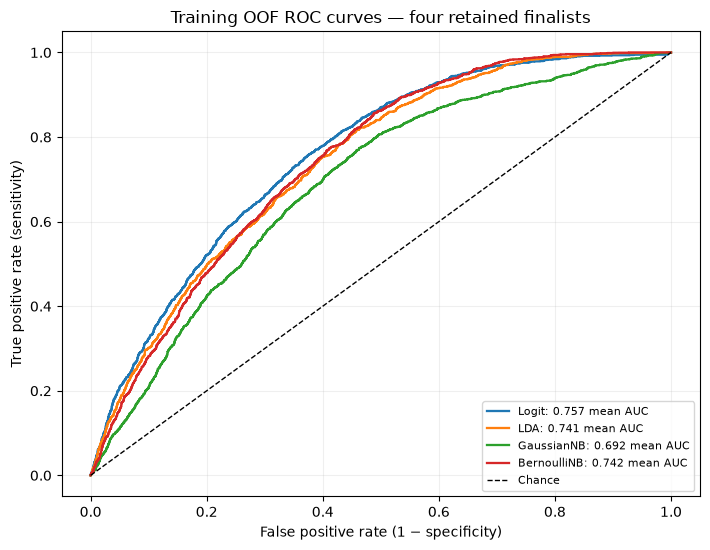

Winner: L1 | Logit | five-fold mean AUC 0.75747


In [11]:
FINALIST_ROWS=[]
OOF_ROWS=[]
FOLD_SCORE_ROWS=[]
for fam in FAMILY_ORDER:
    label=PATH_FINALISTS[fam]
    r=RESULTS[label]
    assert r['status']=='SCORED' and len(r['folds'])==K
    coverage=np.zeros(len(ytr),dtype=int)
    for (fit_idx,val_idx),fr in zip(FOLD_INDICES,r['folds']):
        coverage[val_idx]+=1
        yy=ytr.iloc[val_idx].to_numpy()
        pp=r['oof'][val_idx]
        assert abs(roc_auc_score(yy,pp)-fr['roc_auc'])<1e-12
        assert abs(average_precision_score(yy,pp)-fr['average_precision'])<1e-12
        FOLD_SCORE_ROWS.append({'family':fam,'finalist':label,'fold':fr['fold'],
                'roc_auc':fr['roc_auc'],'average_precision':fr['average_precision']})
    assert np.all(coverage==1)
    FINALIST_ROWS.append({'pathway':fam,'candidate':label,'mean_auc':r['mean_fold_auc'],
            'auc_sd':r['fold_auc_sd'],'auc_se':r['fold_auc_se'],
            'mean_ap':r['mean_fold_ap'],'pooled_oof_auc':r['pooled_oof_auc']})
    for row_id,yy,pp in zip(Xtr.index,ytr.to_numpy(),r['oof']):
        OOF_ROWS.append({'finalist':label,'row_id':int(row_id),'observed':int(yy),'oof_probability':float(pp)})
FINALISTS=pd.DataFrame(FINALIST_ROWS).sort_values(['mean_auc','candidate'],ascending=[False,True]).reset_index(drop=True)
WINNER_LABEL=str(FINALISTS.iloc[0]['candidate'])
WINNER_FAMILY=str(FINALISTS.iloc[0]['pathway'])
WINNER_CONFIG=PATH_FINAL_CONFIGS[WINNER_FAMILY].copy()
WINNER_OOF=np.asarray(RESULTS[WINNER_LABEL]['oof'],dtype=float)
BASE_RATE=float(ytr.mean())
FINALISTS.to_csv(V3_ART/'four_finalists.csv',index=False)
pd.DataFrame(FOLD_SCORE_ROWS).to_csv(V3_ART/'finalist_fold_scores.csv',index=False)
pd.DataFrame(OOF_ROWS).to_csv(V3_ART/'finalist_oof_scores.csv',index=False,float_format='%.17g')
display(FINALISTS[['pathway','candidate','mean_auc','auc_sd','auc_se','mean_ap']].round(5))
fig,ax=plt.subplots(figsize=(7.2,5.6))
for fam in FAMILY_ORDER:
    label=PATH_FINALISTS[fam]
    fpr,tpr,_=roc_curve(ytr,RESULTS[label]['oof'])
    ax.plot(fpr,tpr,lw=1.65,label=f'{fam}: {RESULTS[label]["mean_fold_auc"]:.3f} mean AUC')
ax.plot([0,1],[0,1],'k--',lw=1,label='Chance')
ax.set(xlabel='False positive rate (1 − specificity)',ylabel='True positive rate (sensitivity)',
       title='Training OOF ROC curves — four retained finalists')
ax.legend(loc='lower right',fontsize=8)
ax.grid(alpha=.2);fig.tight_layout()
fig.savefig(V3_ART/'four_finalists_roc.png',dpi=160,bbox_inches='tight')
display(fig);plt.close(fig)
print(f'Winner: {WINNER_LABEL} | five-fold mean AUC {float(FINALISTS.iloc[0]["mean_auc"]):.5f}')

## 9. Winner's training OOF scores and precision–recall behaviour
**Purpose.** See how buyer/nonbuyer scores overlap and whether minority-class detection is informative.

**Method.** Show one class-separated score histogram and one training OOF precision–recall curve, with the observed buyer prevalence as the no-skill reference. A simple reliability summary follows for the 0.20 decision assumption.

**Interpretation.** ROC-AUC/AP measure ordering, not well-calibrated probabilities. The financial cutoff is only decision-optimal under the stated assumptions *and* sufficiently calibrated probabilities.

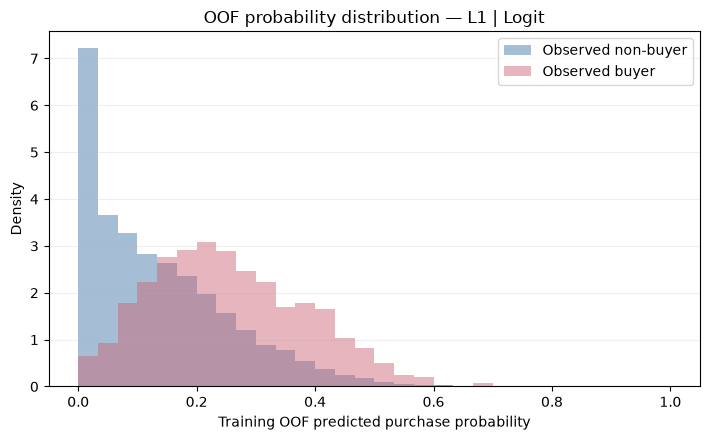

Nonbuyer OOF mean/median=0.1364/0.1088; buyer mean/median=0.2545/0.2415. Scores are below .50 for 99.2% of nonbuyers and 96.4% of buyers; at most 0.0% exceed .90 and the largest is 0.859. This score concentration makes predicted buyer counts sensitive to the chosen cutoff, but does not establish calibration.


In [12]:
fig,ax=plt.subplots(figsize=(7.2,4.5))
for cls,color,name in [(0,'#4477AA','Observed non-buyer'),(1,'#CC6677','Observed buyer')]:
    ax.hist(WINNER_OOF[np.asarray(ytr)==cls],bins=np.linspace(0,1,31),
            density=True,alpha=.48,color=color,label=name)
ax.set(xlabel='Training OOF predicted purchase probability',ylabel='Density',
       title=f'OOF probability distribution — {WINNER_LABEL}')
ax.legend(); ax.grid(axis='y',alpha=.2); fig.tight_layout()
fig.savefig(ARTIFACTS/'training_winner_oof_probability_histogram.png',dpi=180,bbox_inches='tight')
display(fig); plt.close(fig)
hist_rows=[]
for cls,name in [(0,'Observed non-buyer'),(1,'Observed buyer')]:
    values=WINNER_OOF[np.asarray(ytr)==cls]
    hist_rows.append({'observed_group':name,'sessions':len(values),'mean_probability':float(values.mean()),
      'median_probability':float(np.median(values)),'share_below_0.10':float(np.mean(values<.10)),
      'share_below_0.50':float(np.mean(values<.50)),'share_above_0.90':float(np.mean(values>.90)),
      'maximum_probability':float(values.max())})
WINNER_HIST_SUMMARY=pd.DataFrame(hist_rows)
hist_nonbuyer=WINNER_HIST_SUMMARY.loc[WINNER_HIST_SUMMARY.observed_group.eq('Observed non-buyer')].iloc[0]
hist_buyer=WINNER_HIST_SUMMARY.loc[WINNER_HIST_SUMMARY.observed_group.eq('Observed buyer')].iloc[0]
share_high=max(hist_nonbuyer['share_above_0.90'],hist_buyer['share_above_0.90'])
print(f"Nonbuyer OOF mean/median={hist_nonbuyer.mean_probability:.4f}/{hist_nonbuyer.median_probability:.4f}; buyer mean/median={hist_buyer.mean_probability:.4f}/{hist_buyer.median_probability:.4f}. Scores are below .50 for {hist_nonbuyer['share_below_0.50']:.1%} of nonbuyers and {hist_buyer['share_below_0.50']:.1%} of buyers; at most {share_high:.1%} exceed .90 and the largest is {max(hist_nonbuyer['maximum_probability'],hist_buyer['maximum_probability']):.3f}. This score concentration makes predicted buyer counts sensitive to the chosen cutoff, but does not establish calibration.")

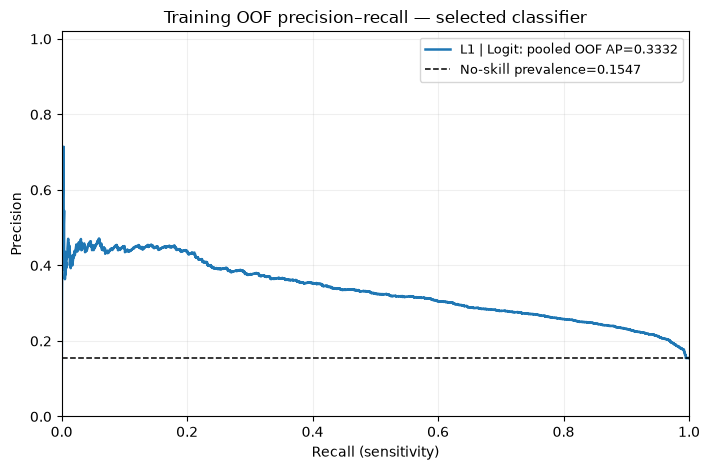

Mean fold AP=0.336226; pooled OOF AP=0.333169; prevalence=0.154704


In [13]:
# A10 — winner OOF precision–recall curve
precision_values,recall_values,_=precision_recall_curve(ytr,WINNER_OOF)
POOLED_AP=float(average_precision_score(ytr,WINNER_OOF))
BASE_RATE=float(ytr.mean())
fig,ax=plt.subplots(figsize=(7.2,4.8))
ax.plot(recall_values,precision_values,lw=1.8,label=f'{WINNER_LABEL}: pooled OOF AP={POOLED_AP:.4f}')
ax.axhline(BASE_RATE,color='black',ls='--',lw=1.1,label=f'No-skill prevalence={BASE_RATE:.4f}')
ax.set(xlabel='Recall (sensitivity)',ylabel='Precision',xlim=(0,1),ylim=(0,1.02),
       title='Training OOF precision–recall — selected classifier')
ax.grid(alpha=.2);ax.legend(fontsize=9);fig.tight_layout()
fig.savefig(V3_ART/'winner_oof_pr.png',dpi=180,bbox_inches='tight')
display(fig);plt.close(fig)
print(f'Mean fold AP={float(FINALISTS.loc[FINALISTS.candidate.eq(WINNER_LABEL),"mean_ap"].iloc[0]):.6f}; pooled OOF AP={POOLED_AP:.6f}; prevalence={BASE_RATE:.6f}')


In [14]:
# Descriptive calibration check, no calibration model is fitted or chosen from holdout.
reliability=pd.DataFrame({'actual':ytr.to_numpy(),'predicted':WINNER_OOF})
reliability['bucket']=pd.cut(reliability.predicted,bins=np.linspace(0,1,11),include_lowest=True)
reliability=reliability.groupby('bucket',observed=True).agg(
    n=('actual','size'),observed_purchase_rate=('actual','mean'),mean_predicted_probability=('predicted','mean')).reset_index()
display(reliability.round(4))
reliability.to_csv(V3_ART/'winner_oof_reliability.csv',index=False)

,bucket,n,observed_purchase_rate,mean_predicted_probability
0,"(-0.001, 0.1]",4106,0.0416,0.0383
1,"(0.1, 0.2]",2579,0.1559,0.1483
2,"(0.2, 0.3]",1748,0.2454,0.2447
3,"(0.3, 0.4]",908,0.3194,0.3448
4,"(0.4, 0.5]",402,0.4453,0.4421
5,"(0.5, 0.6]",103,0.4660,0.5396
6,"(0.6, 0.7]",16,0.4375,0.6349
7,"(0.7, 0.8]",1,0.0000,0.7633
8,"(0.8, 0.9]",1,0.0000,0.8593


## 10. Four threshold references
**Purpose.** Compare classification trade-offs with the hypothetical upselling decision.

**Method.** A prediction of Buy occurs if **p ≥ t**. Use the training buyer prevalence, 0.500, the nearest empirical sensitivity–specificity crossover, and the **fixed assumption-derived 0.200**. Here false positives mean contacting nonbuyers, whereas false negatives mean leaving actual buyers without upsell assistance.

**Payoffs (hypothetical, not observed).** S$3 per agent contact; conditional upsell probability 30% and incremental gross margin S$50. Expected net benefit of contacting an actual buyer = 0.3×50−3 = **S$12**; contacting a nonbuyer = **−S$3**. Thus relative error costs C_FP=3, C_FN=12, and t*=3/(3+12)=**0.20**. Equivalently, contact when 15p−3 > 0 (with equality classified Buy for reproducibility). These costs do not measure any intervention effect from UCI.

,reference,threshold,TP,FP,TN,FN,sensitivity,specificity,precision,hypothetical_relative_loss_SGD
0,Training prevalence,0.1547,1153,3113,5225,373,0.7556,0.6266,0.2703,13815
1,Conventional 0.500,0.5000,55,66,8272,1471,0.0360,0.9921,0.4545,17850
2,Sensitivity–specificity crossover,0.1795,1044,2634,5704,482,0.6841,0.6841,0.2838,13686
3,Cost-based (hypothetical),0.2000,953,2226,6112,573,0.6245,0.7330,0.2998,13554


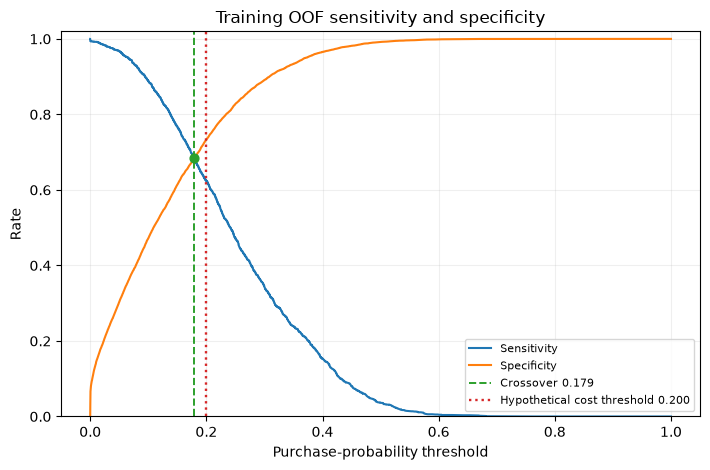

Financial threshold 0.20 is fixed independently of observed confusion matrices.


In [15]:
def threshold_measures(y_true,prob,threshold):
    true=np.asarray(y_true,dtype=int)
    pred=(np.asarray(prob,dtype=float)>=float(threshold)).astype(int)
    tn,fp,fn,tp=confusion_matrix(true,pred,labels=[0,1]).ravel()
    return {'threshold':float(threshold),'TP':int(tp),'FP':int(fp),'TN':int(tn),'FN':int(fn),
            'sensitivity':float(tp/(tp+fn)),'specificity':float(tn/(tn+fp)),
            'precision':float(tp/(tp+fp)) if tp+fp else np.nan,
            'hypothetical_relative_loss_SGD':int(3*fp+12*fn)}
_,_,roc_candidates=roc_curve(ytr,WINNER_OOF,drop_intermediate=False)
cutoffs=np.unique(np.r_[roc_candidates[np.isfinite(roc_candidates)&(roc_candidates>=0)&(roc_candidates<=1)],0.,1.])
THRESHOLD_CURVE=pd.DataFrame([threshold_measures(ytr,WINNER_OOF,t) for t in cutoffs])
THRESHOLD_CURVE['gap']=(THRESHOLD_CURVE.sensitivity-THRESHOLD_CURVE.specificity).abs()
CROSSOVER=THRESHOLD_CURVE.sort_values(['gap','threshold'],kind='stable').iloc[0]
CROSSOVER_THRESHOLD=float(CROSSOVER.threshold)
THRESHOLD_REFS=[('Training prevalence',BASE_RATE),('Conventional 0.500',0.5),
                ('Sensitivity–specificity crossover',CROSSOVER_THRESHOLD),
                ('Cost-based (hypothetical)',0.2)]
THRESHOLD_TABLE=pd.DataFrame([{'reference':label,**threshold_measures(ytr,WINNER_OOF,t)}
                              for label,t in THRESHOLD_REFS])
assert len(THRESHOLD_TABLE)==4
assert THRESHOLD_TABLE[['TP','FP','TN','FN']].sum(axis=1).eq(len(ytr)).all()
assert np.isclose(THRESHOLD_TABLE.loc[3,'threshold'],0.2)
THRESHOLD_TABLE.to_csv(V3_ART/'four_threshold_references.csv',index=False)
THRESHOLD_CURVE.to_csv(V3_ART/'threshold_curves.csv',index=False)
display(THRESHOLD_TABLE.round(4))
fig,ax=plt.subplots(figsize=(7.2,4.8))
ax.plot(THRESHOLD_CURVE.threshold,THRESHOLD_CURVE.sensitivity,label='Sensitivity')
ax.plot(THRESHOLD_CURVE.threshold,THRESHOLD_CURVE.specificity,label='Specificity')
ax.axvline(CROSSOVER_THRESHOLD,ls='--',color='tab:green',lw=1.4,label=f'Crossover {CROSSOVER_THRESHOLD:.3f}')
ax.axvline(0.2,ls=':',color='tab:red',lw=1.7,label='Hypothetical cost threshold 0.200')
ax.scatter([CROSSOVER_THRESHOLD],[float(CROSSOVER.sensitivity)],color='tab:green',s=40,zorder=5)
ax.set(xlabel='Purchase-probability threshold',ylabel='Rate',ylim=(0,1.02),
       title='Training OOF sensitivity and specificity')
ax.grid(alpha=.2);ax.legend(fontsize=8);fig.tight_layout()
fig.savefig(V3_ART/'sensitivity_specificity.png',dpi=160,bbox_inches='tight')
display(fig);plt.close(fig)
print('Financial threshold 0.20 is fixed independently of observed confusion matrices.')

## 11. Cost-assumption sensitivity (no revenue simulation)
**Purpose.** Show how the hypothetical decision changes when the unknown upsell rate differs.

**Method.** Keep the S$3 contact cost and S$50 incremental gross margin fixed. Set conditional upsell success q=20%, 30% or 40%. Theoretical threshold t=s/(q×g), provided the assumed upsell benefit exceeds contact cost.

**Interpretation.** These are *input assumptions*, not estimated purchase uplift. The UCI data contain no agent assignments or upsell outcomes.

In [16]:
COST_SENSITIVITY=pd.DataFrame([{'assumed_upsell_success_q':q,'agent_cost_SGD':3.,
 'incremental_gross_margin_SGD':50.,'net_TP_value_SGD':q*50-3,
 'C_FP_SGD':3.,'C_FN_SGD':q*50-3.,
 'theoretical_probability_cutoff':3/(q*50)}
 for q in [.20,.30,.40]])
assert np.allclose(COST_SENSITIVITY.theoretical_probability_cutoff,[.30,.20,.15])
display(COST_SENSITIVITY.round(4))
COST_SENSITIVITY.to_csv(V3_ART/'upsell_sensitivity.csv',index=False)

,assumed_upsell_success_q,agent_cost_SGD,incremental_gross_margin_SGD,net_TP_value_SGD,C_FP_SGD,C_FN_SGD,theoretical_probability_cutoff
0,0.2,3.0,50.0,7.0,3.0,7.0,0.30
1,0.3,3.0,50.0,12.0,3.0,12.0,0.20
2,0.4,3.0,50.0,17.0,3.0,17.0,0.15


## 12. Frozen reserved-set check and final full-data refit
**Purpose.** Check the already-selected recipe once, then fit the identical family/representation on all records for the final model.

**Method.** Refit the winner on the 9,864 training rows (retuning a predeclared inner CV grid, if selected), check finite parameters and probabilities, perform **one v3 reserved-set** ROC-AUC/AP/threshold check on the original 2,466 records, and only then refit the unchanged recipe on all 12,330 rows. No post-test tuning or candidate change.

**Qualification.** The reserved observations have been used in historical project versions, so this check is held out *for this v3 protocol*, not a pristine lifetime-independent validation.

In [17]:
def validate_fitted_model(model,X,description):
    actual=model.best_estimator_ if isinstance(model,GridSearchCV) else model
    estimator=actual.named_steps['clf']
    numbers=[np.asarray(getattr(estimator,k),dtype=float)
        for k in ('coef_','intercept_','theta_','var_','class_prior_','feature_log_prob_','means_','priors_')
        if hasattr(estimator,k)]
    if not numbers or not all(np.isfinite(a).all() for a in numbers):
        raise RuntimeError(f'{description}: finite parameter audit failed')
    sample=model.predict_proba(X)[:,1]
    if not np.isfinite(sample).all() or ((sample<0)|(sample>1)).any():
        raise RuntimeError(f'{description}: invalid probability output')
    return {'description':description,'finite_parameters':True,
            'probability_min':float(sample.min()),'probability_max':float(sample.max()),
            'chosen_inner_CV_params':model.best_params_ if isinstance(model,GridSearchCV) else {}}

SELECTED_TRAIN_MODEL=build_model(WINNER_FAMILY,WINNER_CONFIG,SAFE)
with warnings.catch_warnings(record=True) as train_warnings:
    warnings.simplefilter('always')
    SELECTED_TRAIN_MODEL.fit(Xtr[SAFE],ytr)
TRAIN_AUDIT=validate_fitted_model(SELECTED_TRAIN_MODEL,Xtr[SAFE],'Frozen training fit')
if any(issubclass(w.category,ConvergenceWarning) for w in train_warnings):
    raise RuntimeError('Frozen training fit convergence warning; inspect before external claims')
print('Frozen training fit passed parameter and probability checks.')

# Do not access any holdout outcome until the winner, four thresholds and training refit
# are fully frozen above. The source is re-read, avoiding any earlier holdout exposure.
reserved=pd.read_csv(data_path)
reserved.insert(0,'_row_id',np.arange(len(reserved),dtype=int))
reserved=reserved.set_index('_row_id').loc[test_ids]
X_test=reserved[SAFE].copy()
X_test[CAT]=X_test[CAT].astype('string')
X_test['Weekend']=X_test['Weekend'].astype(int)
y_test=reserved[TARGET].astype(int)
del reserved
assert len(X_test)==2466 and len(y_test)==2466
test_prob=np.asarray(SELECTED_TRAIN_MODEL.predict_proba(X_test)[:,1],dtype=float)
TEST_AUDIT={'n_test':int(len(y_test)),
   'roc_auc':float(roc_auc_score(y_test,test_prob)),
   'average_precision':float(average_precision_score(y_test,test_prob)),
   'cost_threshold_0_20':threshold_measures(y_test,test_prob,.20)}
display(pd.DataFrame([{'sample':'Reserved v3 check (historically previously used)',
            'n':TEST_AUDIT['n_test'],'ROC-AUC':TEST_AUDIT['roc_auc'],
            'AP':TEST_AUDIT['average_precision'],**TEST_AUDIT['cost_threshold_0_20']}]).round(4))
print('This v3 holdout was examined once AFTER freezing the training selection. Prior historical reuse prevents a pristine-independent-test claim.')

# Final all-data refit uses the same selected pathway recipe, no new model selection.
all_rows=pd.read_csv(data_path)
assert len(all_rows)==12330 and set(all_rows.columns)==EXPECTED
all_rows[CAT]=all_rows[CAT].astype('string')
all_rows['Weekend']=all_rows['Weekend'].astype(int)
FINAL_PIPELINE=build_model(WINNER_FAMILY,WINNER_CONFIG,SAFE)
with warnings.catch_warnings(record=True) as final_warnings:
    warnings.simplefilter('always')
    FINAL_PIPELINE.fit(all_rows[SAFE],all_rows[TARGET].astype(int))
FINAL_AUDIT=validate_fitted_model(FINAL_PIPELINE,all_rows[SAFE],'Final all-data refit')
if any(issubclass(w.category,ConvergenceWarning) for w in final_warnings):
    raise RuntimeError('Final full-data refit convergence warning; inspect before external claims')

RUN_METADATA={'prd':'v3.0','data_sha256':source_hash,
 'random_state':SEED,'training_rows':len(ytr),'test_rows':len(y_test),
 'final_rows':len(all_rows),'cv_folds':K,'inner_folds':INNER_FOLDS,
 'selected_model':WINNER_LABEL,'selected_family':WINNER_FAMILY,
 'selected_recipe':WINNER_CONFIG,'four_finalists':PATH_FINALISTS,
 'test_check':TEST_AUDIT,'train_fit_audit':TRAIN_AUDIT,'final_fit_audit':FINAL_AUDIT,
 'train_warnings':[str(w.message) for w in train_warnings],
 'final_warnings':[str(w.message) for w in final_warnings],
 'historically_pristine_holdout':False,
 'versions':{'python':platform.python_version(),'pandas':pd.__version__,
            'numpy':np.__version__,'scipy':scipy.__version__,'sklearn':sklearn.__version__}}
with (V3_ART/'run_metadata.json').open('w') as f:
    json.dump(RUN_METADATA,f,indent=2,allow_nan=False,default=str)
pd.DataFrame(FOLD_ROWS).drop(columns=['inner_cv_best_params'],errors='ignore').to_csv(
   V3_ART/'all_attempt_fold_scores.csv',index=False)
pd.DataFrame(WARNING_ROWS).to_csv(V3_ART/'fit_warnings.csv',index=False)
pd.DataFrame({'row_id':Xtr.index,'observed':ytr.to_numpy(),
              'winner_oof_probability':WINNER_OOF}).to_csv(V3_ART/'winner_oof.csv',index=False)
pd.DataFrame({'row_id':test_ids,'observed':y_test.to_numpy(),
              'test_probability':test_prob}).to_csv(V3_ART/'frozen_holdout_scores.csv',index=False)
print('Final all-data fit verified for:',WINNER_LABEL)

Frozen training fit passed parameter and probability checks.


,sample,n,ROC-AUC,AP,threshold,TP,FP,TN,FN,sensitivity,specificity,precision,hypothetical_relative_loss_SGD
0,Reserved v3 check (historically previously used),2466,0.7405,0.3272,0.2,237,569,1515,145,0.6204,0.727,0.294,3447


This v3 holdout was examined once AFTER freezing the training selection. Prior historical reuse prevents a pristine-independent-test claim.


Final all-data fit verified for: L1 | Logit


## 13. Findings, interpretation and limitations
**Statistical conclusion** is generated directly from the verified CV, threshold and reserved-set objects below; no old v2 model result is carried over.

**Limitations.** (i) Predictive rather than causal: no observed upsell response, so S$3/S$12 and 0.20 are illustrative only. (ii) AUC/AP do not demonstrate calibration: verify the OOF reliability table before acting on the 0.20 threshold. (iii) Gaussian marginals and within-class NB independence are approximations; LDA assumes shared covariance and class-Gaussian structure, while Logit needs a suitable functional form. (iv) Rare nominal levels, correlated features, duplicates and session-aggregate availability complicate generalisation. (v) Sequential selection can inflate winner CV AUC. (vi) Reserved test observations were used historically and are not pristine across project versions.

In [18]:
row=FINALISTS.iloc[0]
business=THRESHOLD_TABLE.loc[THRESHOLD_TABLE.reference.eq('Cost-based (hypothetical)')].iloc[0]
print('PRD 3.0 PROJECT SUMMARY')
print(f"Four pathway finalists: {PATH_FINALISTS}")
print(f"Winner: {WINNER_LABEL}; mean five-fold ROC-AUC={row.mean_auc:.5f} (SD={row.auc_sd:.5f}; SE={row.auc_se:.5f}); mean AP={row.mean_ap:.5f}.")
print(f"Training buyer prevalence: {BASE_RATE:.4f}; OOF pooled AP: {average_precision_score(ytr,WINNER_OOF):.5f}.")
print(f"Fixed cost cutoff 0.200: TP={int(business.TP)}, FP={int(business.FP)}, TN={int(business.TN)}, FN={int(business.FN)}, sensitivity={business.sensitivity:.4f}, specificity={business.specificity:.4f}, precision={business.precision:.4f}.")
print(f"Reserved v3 check: ROC-AUC={TEST_AUDIT['roc_auc']:.5f}; AP={TEST_AUDIT['average_precision']:.5f} (historical prior use caveat).")
print("All 20 attempts recorded; numerical diagnostics and provenance in artifacts/prd_v3.")
print('Do not interpret illustrative upsell threshold as causal uplift, calibrated economic optimality, or deployment approval.')

PRD 3.0 PROJECT SUMMARY
Four pathway finalists: {'Logit': 'L1 | Logit', 'LDA': 'Operational16 | LDA', 'GaussianNB': 'Operational16 | GaussianNB', 'BernoulliNB': 'B3 | BernoulliNB'}
Winner: L1 | Logit; mean five-fold ROC-AUC=0.75747 (SD=0.01360; SE=0.00608); mean AP=0.33623.
Training buyer prevalence: 0.1547; OOF pooled AP: 0.33317.
Fixed cost cutoff 0.200: TP=953, FP=2226, TN=6112, FN=573, sensitivity=0.6245, specificity=0.7330, precision=0.2998.
Reserved v3 check: ROC-AUC=0.74054; AP=0.32720 (historical prior use caveat).
All 20 attempts recorded; numerical diagnostics and provenance in artifacts/prd_v3.
Do not interpret illustrative upsell threshold as causal uplift, calibrated economic optimality, or deployment approval.
